**Nguyen Duc Minh**

Individual course project — descriptive analysis and basic forecasting on a synthetic dataset.

# MODULE 1 — BUSINESS UNDERSTANDING & PROJECT FOUNDATION {-}
## 1. PROJECT OVERVIEW {-}
### Project Title : Beverage Sales Analytics & Forecasting Dashboard {-}
### Project Goal : {-}
- Business performance analysis
- Understand customer behavior
- Evaluate product effectiveness
- Detect revenue trends
- Predict future sales

### The project will use : {-}
- Python
- Plotly
- Prophet
- Streamlit
  
### To build : {-}
- Analytical pipeline
- Interactive business dashboard.

## 2. BUSINESS OBJECTIVES {-}
### Objective 1 — Analyze Sales Performance {-}
Evaluate:

- Total revenue
- Revenue growth
- Seasonal patterns
- Top-performing products/categories
  
### Objective 2 — Understand Customer Behavior {-}
Analysis:

- B2B vs B2C customers
- Customer purchasing patterns
- High-value customers
- Customer contribution to revenue
  
### Objective 3 — Evaluate Regional Performance {-}
Identify:

- Which region generates the most revenue?
- Market performance by region
- Regional demand patterns
  
### Objective 4 — Forecast Future Sales {-}
Forecast:

- Future monthly sales
- Future category performance
- Seasonal changes revenue

## 3. DATASET OVERVIEW {-}
### Import dataset & preview {-}

In [3]:
import pandas as pd

# Raw data is not stored in the repo (too large). See README for where to get it.
DATA_PATH = 'data/synthetic_beverage_sales_data.csv'

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(8999910, 11)


,Order_ID,Customer_ID,Customer_Type,Product,Category,Unit_Price,Quantity,Discount,Total_Price,Region,Order_Date
0,ORD1,CUS1496,B2B,Vio Wasser,Water,1.66,53,0.10,79.18,Baden-Württemberg,2023-08-23
1,ORD1,CUS1496,B2B,Evian,Water,1.56,90,0.10,126.36,Baden-Württemberg,2023-08-23
2,ORD1,CUS1496,B2B,Sprite,Soft Drinks,1.17,73,0.05,81.14,Baden-Württemberg,2023-08-23
3,ORD1,CUS1496,B2B,Rauch Multivitamin,Juices,3.22,59,0.10,170.98,Baden-Württemberg,2023-08-23
4,ORD1,CUS1496,B2B,Gerolsteiner,Water,0.87,35,0.10,27.40,Baden-Württemberg,2023-08-23


### Check Time Coverage {-}

In [4]:
print(df['Order_Date'].min())
print(df['Order_Date'].max())

2021-01-01
2023-12-30


### Category Overview {-}

In [5]:
print(df['Category'].nunique())
print(df['Category'].unique())

4
<ArrowStringArray>
['Water', 'Soft Drinks', 'Juices', 'Alcoholic Beverages']
Length: 4, dtype: str


### Customer Type Distribution {-}

In [6]:
print(df['Customer_Type'].value_counts())

Customer_Type
B2C    5795405
B2B    3204505
Name: count, dtype: int64


### Region Overview {-}

In [7]:
print(df['Region'].nunique())

16


## 4. BUSINESS QUESTIONS {-}
### Sales Performance Questions {-}
- How has revenue changed over time?
- Are there seasonal patterns in sales?
- Which category generates the most revenue?
- Which product is the best seller?
- Customer Analytics Questions
- B2B or B2C customers generate more revenue?
- Which customer has the highest lifetime value?
- How does discount affect sales?
  
### Regional Analysis Questions {-}
- Which region performs best?
- Are there purchasing behavior differences between regions?

### Forecasting Questions {-}
- How will revenue change in the next 12 months?
- Which category has the strongest growth potential?

## 5. KEY PERFORMANCE INDICATORS (KPIs) {-}
### KPI 1 — Total Revenue {-}
$$ \text{Total Revenue} = \sum(\text{Total Price}) $$

### KPI 2 — Total Orders {-}

### KPI 3 — Average Order Value (AOV) {-}
$$ \text{Average Order Value} = \frac{\text{Revenue}}{\text{Orders}} $$

### KPI 4 — Customer Lifetime Value (CLV) {-}
$$ \text{CLV} = \sum \text{Customer Purchases} $$

### KPI 5 — Revenue Growth Rate {-}
$$ \text{Growth Rate} = \frac{\text{Current Revenue} - \text{Previous Revenue}}{\text{Previous Revenue}} $$

## 6. ANALYTICAL APPROACH {-}
| Technique | Purpose |
|-----------|---------|
| Data Cleaning | Standardize data |
| Exploratory Data Analysis | Understand data patterns |
| Aggregation Analysis | Create business KPIs |
| Customer Segmentation | Segment customers |
| Time Series Analysis | Analyze trends |
| Forecasting | Predict future |

# MODULE 2 — DATA CLEANING & FEATURE ENGINEERING {-}
## 1. DATA CLEANING {-}

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8999910 entries, 0 to 8999909
Data columns (total 11 columns):
 #   Column         Dtype  
---  ------         -----  
 0   Order_ID       str    
 1   Customer_ID    str    
 2   Customer_Type  str    
 3   Product        str    
 4   Category       str    
 5   Unit_Price     float64
 6   Quantity       int64  
 7   Discount       float64
 8   Total_Price    float64
 9   Region         str    
 10  Order_Date     str    
dtypes: float64(3), int64(1), str(7)
memory usage: 1.3 GB


### Convert Date Column {-}

In [9]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

### Check Missing Values {-}

In [10]:
df.isnull().sum()

Order_ID         0
Customer_ID      0
Customer_Type    0
Product          0
Category         0
Unit_Price       0
Quantity         0
Discount         0
Total_Price      0
Region           0
Order_Date       0
dtype: int64

In [11]:
print(df.duplicated().sum())

0


### Validate Quantity & Total Price {-}

In [12]:
df.describe()

,Unit_Price,Quantity,Discount,Total_Price,Order_Date
count,8.999910e+06,8.999910e+06,8.999910e+06,8.999910e+06,8999910
mean,5.818037e+00,2.313813e+01,2.972879e-02,1.307437e+02,2022-07-01 16:18:18.126183
min,3.200000e-01,1.000000e+00,0.000000e+00,3.000000e-01,2021-01-01 00:00:00
25%,1.050000e+00,6.000000e+00,0.000000e+00,8.400000e+00,2021-10-01 00:00:00
50%,1.750000e+00,1.100000e+01,0.000000e+00,2.114000e+01,2022-07-02 00:00:00
75%,3.210000e+00,3.000000e+01,5.000000e-02,6.949000e+01,2023-04-01 00:00:00
max,1.695300e+02,1.000000e+02,1.500000e-01,1.429530e+04,2023-12-30 00:00:00
std,1.470050e+01,2.689321e+01,4.479841e-02,5.096947e+02,NaN


## 2. FEATURE ENGINEERING {-}

### Extract Year & Month {-}

In [13]:
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Quarter'] = df['Order_Date'].dt.quarter
df['Month_Name'] = (df['Order_Date'].dt.strftime('%b'))

# MODULE 3 — EXPLORATORY BUSINESS ANALYSIS {-}
## Turning Data Into Business Insights {-}
## 1. EXECUTIVE KPIs {-}
### Total Revenue {-}

In [14]:
total_revenue = df['Total_Price'].sum()
print(total_revenue)

1176681163.35


*Total revenue over the three years is about 1.18 billion (currency not stated; euro assumed because regions are German states). The dataset is synthetic, so this describes the generated data, not a real company.*

### Total Orders {-}

In [15]:
total_orders = df['Order_ID'].nunique()
print(total_orders)

3000000


### Total Customers {-}

In [16]:
total_customers = df['Customer_ID'].nunique()
print(total_customers)

10000


### Average Order Value {-}

In [17]:
avg_order_value = (
    df.groupby('Order_ID')['Total_Price']
    .sum()
    .mean()
)
print(avg_order_value)

392.22705444999997


*The average order value (~392) is the mean order total across all orders. Orders contain several products, and B2B orders are larger than B2C orders (see the customer section), which raises the average.*

## 2. SALES TREND ANALYSIS {-}
### Monthly Revenue Aggregation {-}

In [18]:
monthly_sales = (
    df.groupby(df['Order_Date'].dt.to_period('M'))['Total_Price']
    .sum()
    .reset_index()
)
monthly_sales['Order_Date'] = (
    monthly_sales['Order_Date']
    .astype(str)
)

In [19]:
import plotly.express as px
fig = px.line(
    monthly_sales,
    x='Order_Date',
    y='Total_Price',
    title='Monthly Revenue Trend'
)

fig.show()

*Monthly revenue moves in a fairly narrow band (about 29M–34.5M) with a mild upward drift. Some of the month-to-month variation is calendar length (February is shorter). The next cell computes yearly totals and growth; with only three years, seasonality here is a pattern to check, not a conclusion.*

## 3. PRODUCT ANALYTICS {-}
### Revenue by Category {-}

In [20]:
category_trend = (
    df.groupby(
        [df['Order_Date'].dt.to_period('M'),'Category']
    )['Total_Price']
    .sum()
    .reset_index()
)
category_trend['Order_Date'] = (
    category_trend['Order_Date']
    .astype(str)
)

In [21]:
fig = px.area(
    category_trend,
    x='Order_Date',
    y='Total_Price',
    color='Category',
    title='Category Revenue Trend'
)

fig.show()

*Alcoholic Beverages is the largest category in every period shown. The share cell below gives exact percentages.*

### Top Product {-}

In [22]:
top_products = (df.groupby('Product')['Total_Price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

In [23]:
fig = px.bar(
    top_products,
    x='Product',
    y='Total_Price',
    title='Top 10 Products'
)
fig.show()

*A small number of products account for a large share of revenue. Revenue ranking reflects price as well as volume, so premium products can rank high with fewer units sold.*

## 4. CUSTOMER ANALYTICS {-}
### B2B vs B2C Revenue {-}

In [24]:
# Revenue contribution
customer_type_sales = (
    df.groupby('Customer_Type')['Total_Price']
    .sum()
    .reset_index()
)
customer_type_sales

,Customer_Type,Total_Price
0,B2B,9.016196e+08
1,B2C,2.750616e+08


In [25]:
# Order contribution
customer_type_orders = (
    df.groupby('Customer_Type')['Order_ID']
    .nunique()
    .reset_index()
)
customer_type_orders 

,Customer_Type,Order_ID
0,B2B,1068808
1,B2C,1931192


In [26]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Create subplot
fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{'type':'domain'}, {'type':'domain'}]],
    subplot_titles=(
        'Revenue Share',
        'Order Share'
    )
)

# Revenue pie chart
fig.add_trace(
    go.Pie(
        labels=customer_type_sales['Customer_Type'],
        values=customer_type_sales['Total_Price'],
        name='Revenue'
    ),
    row=1,
    col=1
)

# Order pie chart
fig.add_trace(
    go.Pie(
        labels=customer_type_orders['Customer_Type'],
        values=customer_type_orders['Order_ID'],
        name='Orders'
    ),
    row=1,
    col=2
)

# Layout
fig.update_layout(
    title_text='B2B vs B2C: Revenue and Order Share',
    template='plotly_white'
)

fig.show()

*B2B accounts for most of the revenue (76.6%) from a minority of orders (35.6%), so B2B orders are larger on average. B2C accounts for most orders.*

### Top Customers {-}

In [27]:
top_customers = (
    df.groupby('Customer_ID')['Total_Price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
top_customers

,Customer_ID,Total_Price
0,CUS3866,367741.61
1,CUS2190,359547.51
2,CUS5120,356102.09
3,CUS8215,354744.41
4,CUS9241,353829.40
5,CUS1479,350365.24
6,CUS2662,348987.45
7,CUS448,345834.59
8,CUS9989,342045.99
9,CUS4834,340644.61


*The top customers each represent a very small share of total revenue (see the concentration cell below), so revenue is not dependent on a few accounts.*

## 5. REGIONAL ANALYTICS {-}
### Revenue by Region {-}

In [28]:
region_sales = (
    df.groupby('Region')['Total_Price']
    .sum()
    .reset_index()
)

In [29]:
fig = px.bar(
    region_sales,
    x='Region',
    y='Total_Price',
    title='Revenue by Region'
)

fig.show()

*Revenue by region is fairly similar across the 16 regions (roughly 65M–82M). Without population or market-size data, this shows size, not market penetration.*

## 6. DISCOUNT & PROMOTION ANALYTICS {-}
### PRODUCTS MOST FREQUENTLY DISCOUNTED {-}

In [30]:
discounted_products = (
    df[df['Discount'] > 0]
    .groupby('Product')
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name='Discount_Count')
)

In [31]:
fig = px.line(
    discounted_products,
    x='Product',
    y='Discount_Count',
    title='Most Frequently Discounted Products'
)

fig.show()

*The most frequently discounted products are mostly juices and waters. These counts depend on how many order lines each product has, so the share of lines discounted would be a fairer comparison.*

In [32]:
# Top 10 most frequently discounted products
top_discount_products = (
    df[df['Discount'] > 0]
    .groupby('Product')
    .agg({
        'Discount': 'count',
        'Quantity': 'sum',
        'Total_Price': 'sum'
    })
    .reset_index()
)

# Rename columns
top_discount_products.columns = [
    'Product',
    'Discount_Count',
    'Total_Quantity_Sold',
    'Revenue'
]

# Keep top 10 by discount frequency
top_discount_products = (
    top_discount_products
    .sort_values(
        by='Discount_Count',
        ascending=False
    )
    .head(10)
)

In [33]:
fig = px.scatter(
    top_discount_products,
    x='Discount_Count',
    y='Total_Quantity_Sold',
    size='Revenue',
    color='Product',
    hover_name='Product',
    title='Top Discounted Products: Discount vs Demand',
    opacity=0.7
)

fig.show()

### DOES DISCOUNT INCREASE REVENUE ? {-}

In [34]:
discount_revenue_trend = (
    df.groupby(
        df['Order_Date'].dt.to_period('M')
    )
    .agg({
        'Discount':'mean',
        'Total_Price':'sum'
    })
    .reset_index()
)
discount_revenue_trend['Order_Date'] = (
    discount_revenue_trend['Order_Date']
    .astype(str)
)

In [35]:
import plotly.graph_objects as go

fig = go.Figure()

# Revenue line
fig.add_trace(
    go.Scatter(
        x=discount_revenue_trend['Order_Date'],
        y=discount_revenue_trend['Total_Price'],
        name='Revenue',
        yaxis='y1'
    )
)

# Discount line
fig.add_trace(
    go.Scatter(
        x=discount_revenue_trend['Order_Date'],
        y=discount_revenue_trend['Discount'],
        name='Average Discount',
        yaxis='y2'
    )
)

# Layout
fig.update_layout(
    title='Discount vs Revenue Over Time',
    
    yaxis=dict(
        title='Revenue'
    ),
    
    yaxis2=dict(
        title='Avg Disct',
        overlaying='y',
        side='right'
    ),
    
    template='plotly_white'
)

fig.show()

*Average monthly discount stays in a very narrow band (about 0.0294–0.0298), so this chart cannot show whether discounts affect revenue. The comparison below (quantity by discount level and customer type) is more informative, but it is still not causal: discounts may be assigned by order size or customer type.*

# MODULE 4 — ADVANCED ANALYTICS & FORECASTING {-}
## 1. TIME SERIES PREPARATION {-}

In [36]:
monthly_sales.columns = ['ds', 'y']

## 2. TREND & SEASONALITY ANALYSIS {-}
### Monthly Revenue Distribution Chart {-}

In [37]:
fig = px.histogram(
    monthly_sales,
    x='y',
    nbins=50,
    title='Monthly Revenue Distribution'
)

fig.show()

In [38]:
from scipy.stats import skew
skewness = skew(monthly_sales['y'])
print(f"Skewness: {skewness:.4f}")

Skewness: -0.7720


## 3. PROPHET FORECASTING {-}
### Revenue forecasting model for the next 12 months {-}

In [39]:
from prophet import Prophet

# Few data points (36 months): use a low-order yearly seasonality to limit overfitting
model = Prophet(
    yearly_seasonality=3,
    weekly_seasonality=False,
    daily_seasonality=False
)

/opt/homebrew/Cellar/jupyterlab/4.3.5/libexec/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


13:55:17 - cmdstanpy - INFO - Chain [1] start processing
13:55:17 - cmdstanpy - INFO - Chain [1] done processing


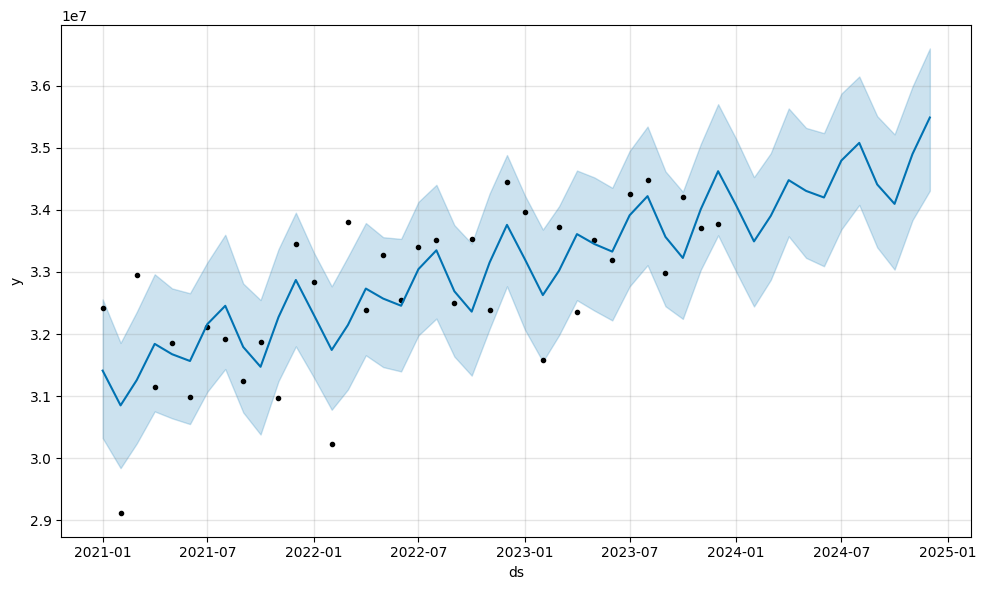

In [40]:
# Dates are month starts, so the future dates must also be month starts ('MS')
model.fit(monthly_sales)
future = model.make_future_dataframe(
    periods=12,
    freq='MS'
)
forecast = model.predict(future)
forecast_fig = model.plot(forecast)

*The model projects revenue for the next 12 months with a mild upward trend and a yearly pattern. The forecast is only as reliable as the backtest at the end of this notebook shows.*

### Components that cause forecast changes {-}

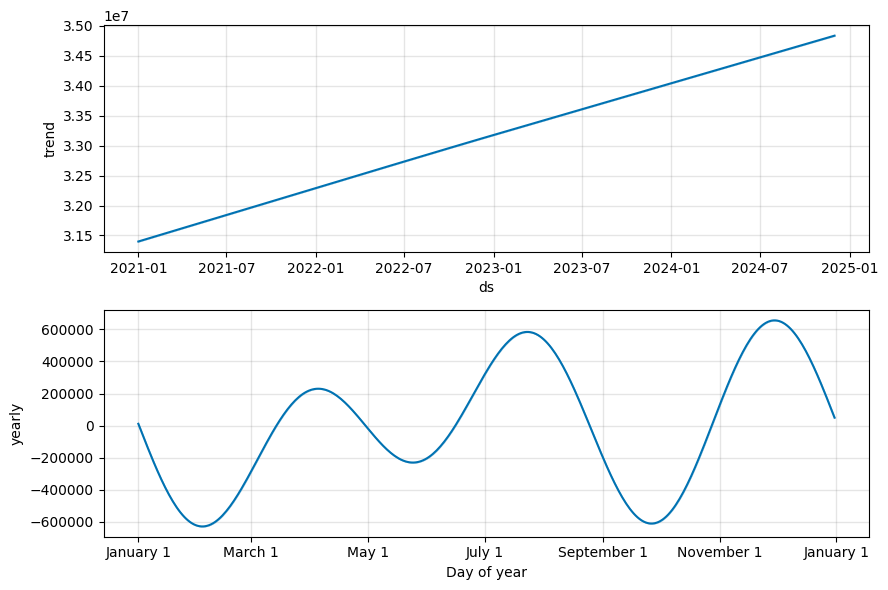

In [41]:
component_fig = model.plot_components(forecast)

*The trend component rises gently over the period. The yearly component is estimated from only three cycles, so it should be read as indicative.*

In [42]:
categories = df['Category'].unique()
category_forecasts = {}

for category in categories:

    # Filter category
    category_df = df[
        df['Category'] == category
    ]

    # Monthly aggregation
    monthly_category_sales = (
        category_df
        .groupby(
            category_df['Order_Date']
            .dt.to_period('M')
        )['Total_Price']
        .sum()
        .reset_index()
    )

    # Rename columns for Prophet
    monthly_category_sales.columns = ['ds', 'y']

    # Convert date
    monthly_category_sales['ds'] = pd.to_datetime(
        monthly_category_sales['ds'].astype(str)
    )

    # Remove invalid values
    monthly_category_sales = (
        monthly_category_sales[
            monthly_category_sales['y'] > 0
        ]
    )

    # Skip if too few rows
    if len(monthly_category_sales) < 12:
        continue

    # Build Prophet model
    model = Prophet(
        yearly_seasonality=3,
        weekly_seasonality=False,
        daily_seasonality=False
    )

    # Train model
    model.fit(monthly_category_sales)

    # Future dates
    future = model.make_future_dataframe(
        periods=12,
        freq='MS'
    )

    # Predict
    forecast = model.predict(future)

    # Store result
    category_forecasts[category] = forecast

13:55:18 - cmdstanpy - INFO - Chain [1] start processing
13:55:19 - cmdstanpy - INFO - Chain [1] done processing
13:55:20 - cmdstanpy - INFO - Chain [1] start processing
13:55:20 - cmdstanpy - INFO - Chain [1] done processing
13:55:20 - cmdstanpy - INFO - Chain [1] start processing
13:55:21 - cmdstanpy - INFO - Chain [1] done processing
13:55:22 - cmdstanpy - INFO - Chain [1] start processing
13:55:22 - cmdstanpy - INFO - Chain [1] done processing


In [43]:
future_predictions = []

for category, forecast in category_forecasts.items():

    future_only = forecast.tail(12)[
        ['ds', 'yhat']
    ].copy()

    future_only['Category'] = category

    future_predictions.append(future_only)

future_predictions = pd.concat(
    future_predictions
)

In [44]:
fig = px.line(
    future_predictions,
    x='ds',
    y='yhat',
    color='Category',
    title='Category Revenue Forecast'
)

fig.show()

*Alcoholic Beverages is forecast to remain the largest category, which follows from its current share. Category forecasts come from separate models and are not constrained to add up to the total forecast.*

In [45]:
Alcoholic_forecast = category_forecasts['Alcoholic Beverages']

fig = px.line(
    Alcoholic_forecast,
    x='ds',
    y='yhat',
    title='Alcoholic Beverages Sales Forecast'
)

fig.show()

## Checks added after review

In [46]:
# Yearly revenue and growth (the last year ends on 30 Dec)
yearly = df.groupby('Year')['Total_Price'].sum()
print(yearly.round(0))
print((yearly.pct_change() * 100).round(1).dropna().rename('growth %'))

Year
2021    380046647.0
2022    394859780.0
2023    401774736.0
Name: Total_Price, dtype: float64
Year
2022    3.9
2023    1.8
Name: growth %, dtype: float64


In [47]:
# Category share of revenue
cat_share = df.groupby('Category')['Total_Price'].sum().sort_values(ascending=False)
print((cat_share / cat_share.sum() * 100).round(1))

Category
Alcoholic Beverages    77.5
Juices                 11.3
Soft Drinks             7.0
Water                   4.2
Name: Total_Price, dtype: float64


In [48]:
# Customer concentration
cust = df.groupby('Customer_ID')['Total_Price'].sum().sort_values(ascending=False)
print('Top customer share  :', round(cust.iloc[0] / cust.sum() * 100, 3), '%')
print('Top 10% customers   :', round(cust.head(len(cust)//10).sum() / cust.sum() * 100, 1), '%')

Top customer share  : 0.031 %
Top 10% customers   : 24.6 %


In [49]:
# Discount vs quantity, by customer type (descriptive only - not causal)
tmp = df.assign(Discount=df['Discount'].round(2))
print(tmp.groupby(['Customer_Type', 'Discount']).agg(lines=('Order_ID', 'size'), avg_quantity=('Quantity', 'mean')).round(1))

                          lines  avg_quantity
Customer_Type Discount                       
B2B           0.05      1438899          33.9
              0.10      1384589          62.1
              0.15       381017          71.3
B2C           0.00      5795405           8.0


## Forecast backtest
Train on 2021–2022 and predict 2023, then compare with the actual 2023 revenue and with a naive baseline (same month of the previous year).

In [50]:
import numpy as np

ms = monthly_sales.copy()
ms['ds'] = pd.to_datetime(ms['ds'])   # convert first: comparing strings would misplace Jan 2023
train = ms[ms['ds'] < '2023-01-01']
test = ms[ms['ds'] >= '2023-01-01']

bt_model = Prophet(yearly_seasonality=3, weekly_seasonality=False, daily_seasonality=False)
bt_model.fit(train)
pred = bt_model.predict(test[['ds']])

naive = train.set_index('ds')['y'].reindex(test['ds'] - pd.DateOffset(months=12)).values
mape = lambda a, p: np.mean(np.abs((a - p) / a)) * 100
print('Prophet MAPE        :', round(mape(test['y'].values, pred['yhat'].values), 2), '%')
print('Same-month baseline :', round(mape(test['y'].values, naive), 2), '%')

13:55:23 - cmdstanpy - INFO - Chain [1] start processing
13:55:23 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAPE        : 2.37 %
Same-month baseline : 2.11 %


*If Prophet does not clearly beat the same-month baseline, the forecast adds little beyond "next year looks like last year". Read the result above before drawing conclusions.*

## Limitations
- Synthetic data: patterns may reflect how it was generated.
- Three years of history only.
- No cost, margin, promotion calendar or market-size data.
- Forecasts use revenue history only.